In [1]:
'''2C. Implement the CNN model for classifying Sign Language MNIST by dividing the
model into following 4 stages:
a. Loading and preprocessing the image data
b. Defining the model's architecture
c. Training the model
d. Estimating the model's performance'''

"2C. Implement the CNN model for classifying Sign Language MNIST by dividing the\nmodel into following 4 stages:\na. Loading and preprocessing the image data\nb. Defining the model's architecture\nc. Training the model\nd. Estimating the model's performance"

In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Flatten,Dense,Dropout
from sklearn.model_selection import train_test_split

In [11]:
train=pd.read_csv(r"F:\lp4\LP IV Updated Datasets\FNN and CNN\Sign Language MNIST\sign_mnist_train.csv")
test=pd.read_csv(r"F:\lp4\LP IV Updated Datasets\FNN and CNN\Sign Language MNIST\sign_mnist_test.csv")

In [12]:
print(train.shape,test.shape)

(27455, 785) (7172, 785)


In [15]:
x_train=train.drop('label',axis=1).values
x_test=test.drop('label',axis=1).values

y_train=train['label'].values
y_test=test['label'].values

In [16]:
x_train=x_train.reshape(-1,28,28,1)
x_test=x_test.reshape(-1,28,28,1)

x_train=x_train.astype('float32')/255.0
x_test=x_test.astype('float32')/255.0

In [17]:
print(x_train.shape,x_test.shape)

(27455, 28, 28, 1) (7172, 28, 28, 1)


In [35]:
model=Sequential([
    Conv2D(28,(1,1),activation='relu',input_shape=(28,28,1)),
    MaxPooling2D((2,2)),
    Conv2D(56,(1,1),activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),

    Dense(112,activation='relu'),
    Dropout(0.5),
    Dense(25,activation='softmax')         

    
           
])

C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [36]:
print(len(np.unique(y_train)))

24


In [37]:
model.compile(
    optimizer='Adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [38]:
history=model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 12s 44ms/step - accuracy: 0.1024 - loss: 3.0308 - val_accuracy: 0.2964 - val_loss: 2.4964
Epoch 2/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step - accuracy: 0.2701 - loss: 2.2983 - val_accuracy: 0.5117 - val_loss: 1.7163
Epoch 3/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.3610 - loss: 1.9129 - val_accuracy: 0.6194 - val_loss: 1.3526
Epoch 4/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step - accuracy: 0.4207 - loss: 1.7002 - val_accuracy: 0.6657 - val_loss: 1.1947
Epoch 5/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.4526 - loss: 1.5808 - val_accuracy: 0.6868 - val_loss: 1.0190
Epoch 6/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.4800 - loss: 1.4914 - val_accuracy: 0.7411 - val_loss: 0.8679
Epoch 7/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.5032 - loss: 1.4049 - val_accuracy: 0.7673 - val_loss: 0.8057
Epoch 8/11
194/194 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.5167 - loss: 1.3693 - val_a

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6392 - loss: 1.0147


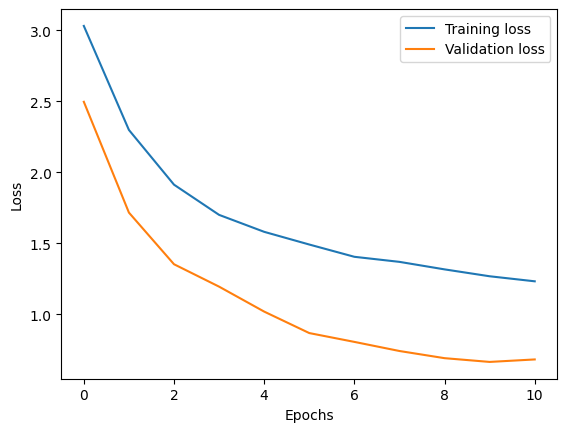

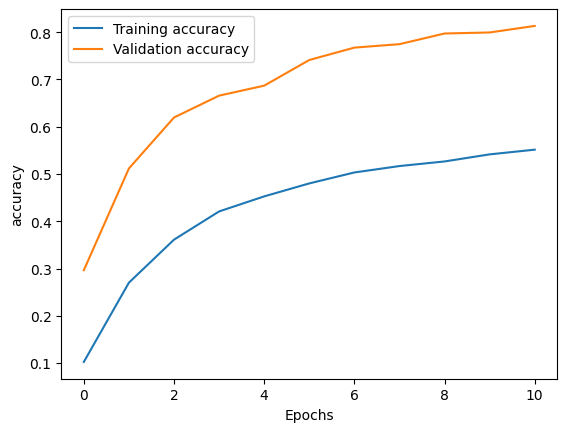

In [41]:
test_loss,test_accuracy=model.evaluate(x_test,y_test)


plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'],label='Validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


plt.plot(history.history['accuracy'],label='Training accuracy')
plt.plot(history.history['val_accuracy'],label='Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()
plt.show()

